In [129]:
#Displaying
import networkx as nx
import matplotlib.pyplot as plt

def graphDisplay(adjacent_list, filename="graphs_output.jpg"):
    graph = nx.Graph()
    for i in range(len(adjacent_list)):
        graph.add_node(i + 1)
    for index, row in enumerate(adjacent_list):
        for i in row:
            graph.add_edge(i, index + 1)

    _, ax = plt.subplots(figsize=(7,7))
    pos = nx.circular_layout(graph)

    bg_circle = plt.Circle(
        (0, 0),
        radius=1.0,
        color="lightgray",
        fill=False,
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        zorder=1
    )
    ax.add_patch(bg_circle)

    #For yupiter implementation to see output
    nx.draw_networkx_nodes(
        graph, pos, node_color="skyblue", node_size=700, ax=ax
    )
    nx.draw_networkx_labels(
        graph, pos, font_weight="bold", ax=ax
    )
    nx.draw_networkx_edges(
        graph, pos, edge_color="gray", ax=ax
    )

    ax.set_aspect("equal")
    plt.axis("off")

    plt.savefig(filename, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

# Adjacent list conversion

def adjacentListToAdjacentMatrix(adjacent_list):
    matrix = []
    for i in range(len(adjacent_list)):
        row = [0] * len(adjacent_list)
        for j in adjacent_list[i]:
            row[j - 1] = 1
        matrix.append(row)
    return matrix

def adjacentListToIncidentsMatrix(adjacent_list):
    matrix = []
    for i in range(len(adjacent_list)):
        for j in adjacent_list[i]:
            if j - 1 >= i:
                col = [0] * len(adjacent_list)
                col[i] = 1
                col[j-1] = 1
                matrix.append(col)
    return matrix

# Adjacent matrix conversion

def adjacentMatrixToIncidentsMatrix(adjacent_matrix):
    matrix = []
    for i in range(len(adjacent_matrix)):
        for j in range(i + 1, len(adjacent_matrix)):
            if adjacent_matrix[i][j] == 1:
                col = [0] * len(adjacent_matrix)
                col[i] = 1
                col[j] = 1
                matrix.append(col)
    return matrix

def adjacentMatrixToAdjacentList(adjacent_matrix):
    adj_list = []
    for i in range(len(adjacent_matrix)):
        row = []
        for j in range(len(adjacent_matrix)):
            if adjacent_matrix[i][j] == 1:
                row.append(j + 1)
        adj_list.append(row)
    return adj_list

# Incident matrix conversion

def incidentsMatrixToAdjacentList(incidents_matrix):
    matrix = [] * len(incidents_matrix[0])
    for _ in range(len(incidents_matrix[0])):
        matrix.append([] * len(incidents_matrix[0]))
    for i in incidents_matrix:
        first, second = -1,-1
        for j in range(len(incidents_matrix[0])):
            if i[j] == 1:
                if first == -1:
                    first = j
                else:
                    second = j
                    break
        matrix[first].append(second + 1)
        matrix[second].append(first + 1)
            

    return matrix

def incidentsMatrixToAdjacentMatrix(incidents_matrix):
    matrix = [] * len(incidents_matrix[0])
    for _ in range(len(incidents_matrix[0])):
        matrix.append([0] * len(incidents_matrix[0]))
    for i in incidents_matrix:
        first, second = -1,-1
        for j in range(len(incidents_matrix[0])):
            if i[j] == 1:
                if first == -1:
                    first = j
                else:
                    second = j
                    break
        matrix[first][second] = 1
        matrix[second][first] = 1
            

    return matrix

#Graph generation
import random

def generateGraph(node_num = None, edge_num=None, random_chance_per_edge=None):
    if node_num == None:
        raise ValueError("Graph without node can't be created")
    if (edge_num == None and random_chance_per_edge == None) or (edge_num != None and random_chance_per_edge != None):
        raise ValueError("Chose one option edge_num (default) or random_chance_per_edge")

    outputAdjacentList = []
    if random_chance_per_edge != None:
        if (random_chance_per_edge < 0 or random_chance_per_edge > 1):
            raise("Bad random chance number")
        for _ in range(node_num):
            outputAdjacentList.append([])
        for i in range(node_num):
            for j in range(i + 1, node_num):
                if random_chance_per_edge >= random.random():
                    outputAdjacentList[i].append(j + 1)
                    outputAdjacentList[j].append(i + 1)
    elif edge_num != None:
        if edge_num < 0 or edge_num > (node_num* (node_num - 1)) // 2:
            raise ValueError("Bad edge number")
        matrix = [] * node_num
        for _ in range(node_num):
            matrix.append([0] * node_num)
        edges_generated = 0
        while edges_generated < edge_num:
            x, y = random.randint(0, node_num - 1), random.randint(0, node_num - 1)
            if x == y:
                continue
            if matrix[x][y] == 0:
                matrix[x][y] = 1
                matrix[y][x] = 1
                edges_generated = edges_generated + 1

        outputAdjacentList = adjacentMatrixToAdjacentList(matrix)

    return outputAdjacentList

# Graph parameters

def graphNodes(adjacent_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    return len(adjacent_list)

def graphEdges(adjacent_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    return len(adjacentListToIncidentsMatrix(adjacent_list))

def deleteNode(adjacent_list=None, node_num=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if node_num == None:
        raise ValueError("Node number index [1...n] required!")
    node_num = node_num - 1
    # Create copy to not modify passed graph
    output_adjacent_list = [list(nodes) for nodes in adjacent_list]
    for connected_nodes in output_adjacent_list[node_num]:
        output_adjacent_list[connected_nodes - 1].remove(node_num + 1)
    return output_adjacent_list

def deleteEdge(adjacent_list=None, edge=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if edge == None or len(edge) != 2:
        raise ValueError("Edge in format [a,b] or (a,b), where a and b are nodes index 1..n required!")
    node1 = edge[0] - 1
    node2 = edge[1] - 1
    # Create copy to not modify passed graph
    output_adjacent_list = [list(nodes) for nodes in adjacent_list]
    output_adjacent_list[node1].remove(node2 + 1)
    output_adjacent_list[node2].remove(node1 + 1)
    return output_adjacent_list


In [130]:
graph_graphical = [4, 2, 2, 3, 2, 1, 4, 2, 2, 2, 2]
test = [4, 2, 2, 3, 2, 1, 4, 2, 2, 2, 2]

In [131]:
# Graph graphical

def checkIfGraphicSequence(sequence=None):
    if sequence == None:
        raise ValueError("Sequence is required!")
    s = sorted(sequence, reverse=True)
    while s:
        d = s.pop(0)
        if d > len(s):
            return False
        for i in range(d):
            s[i] -= 1
            if s[i] < 0:
                return False
        s.sort(reverse=True)
    return True

def graphicalSequenceToAdjacentList(sequence=None):
    if sequence == None:
        raise ValueError("Sequence is required!")
    if checkIfGraphicSequence(sequence=sequence) == False:
        raise ValueError("Sequence is not graphical!")
    
    sequence = list(sequence)
    sequence.sort(reverse=True)
    indexed_seq = [[val, idx] for idx, val in enumerate(sequence)]

    adjacent_list = []
    for _ in range(len(sequence)):
        adjacent_list.append([])
    
    while True:
        if indexed_seq == []:
            break

        for i in range(indexed_seq[0][0]):
            indexed_seq[i + 1][0] = indexed_seq[i + 1][0] - 1
            adjacent_list[indexed_seq[0][1]].append(indexed_seq[i + 1][1] + 1)
            adjacent_list[indexed_seq[i + 1][1]].append(indexed_seq[0][1] + 1)

        if indexed_seq != []:
            indexed_seq = indexed_seq[1:]

        indexed_seq.sort(reverse=True, key=lambda x: x[0])
        indexed_seq = [[elem[0], elem[1]] for elem in indexed_seq if elem[0] != 0]



    return adjacent_list

In [132]:
print(checkIfGraphicSequence(graph_graphical))
print(checkIfGraphicSequence([4,4,3,1,2]))
print(checkIfGraphicSequence([1,3,2,3,2,4,1]))
print(checkIfGraphicSequence([1,3,3,4,2,3,1]))

True
False
True
False


In [133]:
print(graphicalSequenceToAdjacentList([1,3,2,3,2,4,1]))
print(graphicalSequenceToAdjacentList(graph_graphical))

[[2, 3, 4, 5], [1, 3, 4], [1, 2, 5], [1, 2], [1, 3], [7], [6]]
[[2, 3, 4, 5], [1, 3, 6, 7], [1, 2, 6], [1, 7], [1, 11], [2, 3], [2, 4], [9, 10], [8, 10], [8, 9], [5]]


In [134]:
# Graph edge rotations

def change_pair(adjacent_list=None, a=None, b=None, c=None, d=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if a == None or b == None or c == None or d ==None:
        raise ValueError("Parameters (a,b) <=> (c,d) required! Indexed form 1 do ...")

    # It's easier task with adjacent_matrix
    adjacent_matrix = adjacentListToAdjacentMatrix(adjacent_list=adjacent_list)

    # Nodes are index 1..n, but in program we index everything 0..n
    a = a - 1
    b = b - 1
    c = c - 1
    d = d - 1
    # Check if new edge alerady exists
    if adjacent_matrix[a][d] == 1 or adjacent_matrix[b][c] == 1:
        return False, adjacent_list # This edge already exist
    elif a == d or b == c:
        return False, adjacent_list # We don't create loop edges
    elif adjacent_matrix[a][b] != 1 or adjacent_matrix[c][d] != 1:
        return False, adjacent_list # Passed edges doesn't exist, there is nothing to change

    # Erase old connections
    adjacent_matrix[a][b] = 0
    adjacent_matrix[b][a] = 0
    adjacent_matrix[c][d] = 0
    adjacent_matrix[d][c] = 0

    # Create new connections
    adjacent_matrix[a][d] = 1
    adjacent_matrix[d][a] = 1
    adjacent_matrix[b][c] = 1
    adjacent_matrix[c][b] = 1

    adjacent_list = adjacentMatrixToAdjacentList(adjacent_matrix)
    return True, adjacent_list

def randomize_pair(adjacent_list=None, randomize_cycles=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if randomize_cycles == None:
        raise ValueError("Number of randomizations required!")
    
    edges_found = 0
    for nodes in adjacent_list:
        for _ in nodes:
            edges_found += 1
    edges_found = edges_found // 2

    # Check if minimu 2 edges exists
    if edges_found < 2:
        return adjacent_list
    # Check if it's not full graph
    elif edges_found >= (len(adjacent_list) * (len(adjacent_list) - 1)) / 2:
        return adjacent_list

    rotations_made = 0
    while rotations_made < randomize_cycles:
        a = random.randint(1, len(adjacent_list))
        b = random.randint(1, len(adjacent_list))
        c = random.randint(1, len(adjacent_list))
        d = random.randint(1, len(adjacent_list))
        done, adjacent_list = change_pair(adjacent_list, a, b, c, d)
        # If edge changed increment counter
        if done:
            rotations_made = rotations_made + 1

    return adjacent_list

[[2, 3, 4, 5], [1, 3, 4], [1, 2, 5], [1, 2], [1, 3], [7], [6]]


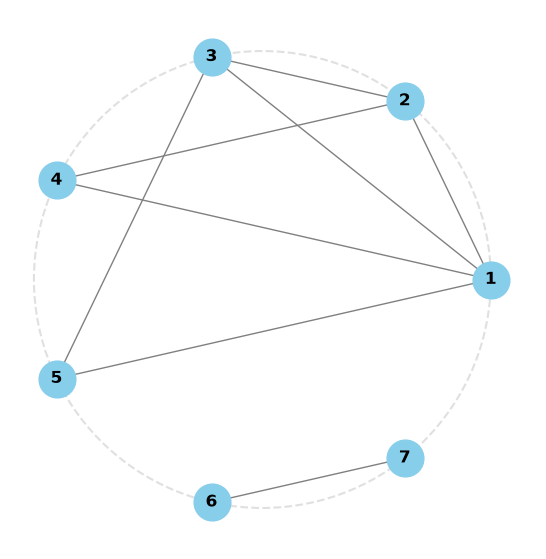

In [135]:
adj_graph = graphicalSequenceToAdjacentList([4,3,3,2,2,1,1])
print(adj_graph)
graphDisplay(adj_graph)

8
8
True
[[3, 4, 5, 7], [3, 4, 6], [1, 2, 5], [1, 2], [1, 3], [2], [1]]


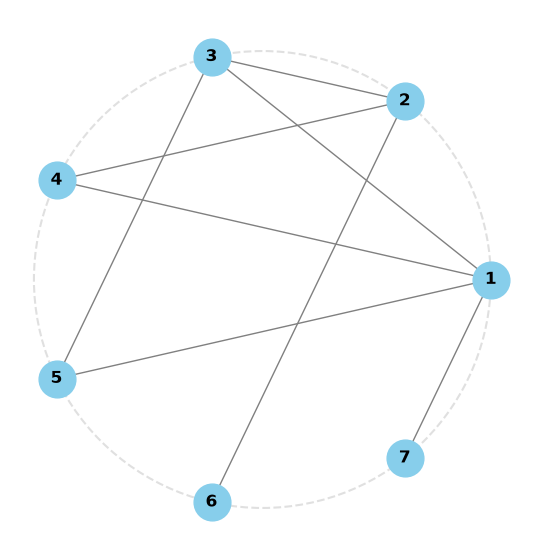

In [136]:
adj_graph = graphicalSequenceToAdjacentList([4,3,3,2,2,1,1])
print(graphEdges(adj_graph))
val, adj_graph = change_pair(adj_graph, 1, 2,6, 7)
print(graphEdges(adj_graph))
print(val)
print(adj_graph)
graphDisplay(adj_graph)

8
8


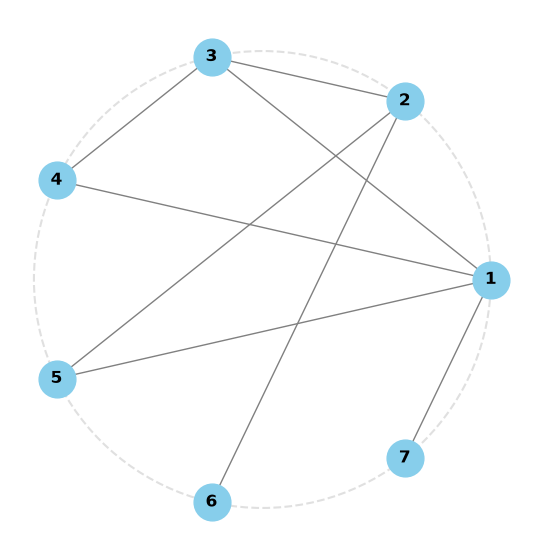

In [137]:
adj_graph = graphicalSequenceToAdjacentList([4,3,3,2,2,1,1])
print(graphEdges(adj_graph))
adj_graph = randomize_pair(adj_graph, 10)
print(graphEdges(adj_graph))
graphDisplay(adj_graph)


In [138]:
# Strongly connected Component (Spojna skladowa)

def graphComponent_R(component_num=None, node_num=None, adjacent_list=None, nodes=None):
    if component_num == None:
        raise ValueError("Component number required!")
    if node_num == None:
        raise ValueError("Node number required!")
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if nodes == None:
        raise ValueError("Nodes list [[node_num, component_num],..] required!")

    for neigthbour_node in adjacent_list[node_num]:
        neigthbour_node = neigthbour_node - 1 # In adjacent list we store nodes idnex 1...n, byt we want to use 0...n
        if nodes[neigthbour_node][1] == -1:
            nodes[neigthbour_node][1] = component_num
            graphComponent_R(component_num, neigthbour_node, adjacent_list, nodes)


def graphComponents(adjacent_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")

    # components = {}
    # [[node_num, component_num], ...]
    nodes = [[node_num, -1] for node_num in range(len(adjacent_list))]
    component_num = 0
    for node_num in range(len(adjacent_list)):
        if nodes[node_num][1] == -1:
            component_num = component_num + 1
            nodes[node_num][1] = component_num
            graphComponent_R(component_num, node_num, adjacent_list, nodes)

    # Return dictionary with componets gropu {'component number': [list of node indexed 1..n]}
    components = {}
    for node_num, component_num in nodes:
        components.setdefault(component_num, []).append(node_num + 1)
    return components


[[2, 3, 4, 5], [1, 3, 4], [1, 2, 5], [1, 2], [1, 3], [7], [6]]
[[2, 3, 4, 5], [1, 3, 4], [1, 2], [1, 2], [1], [7], [6]]


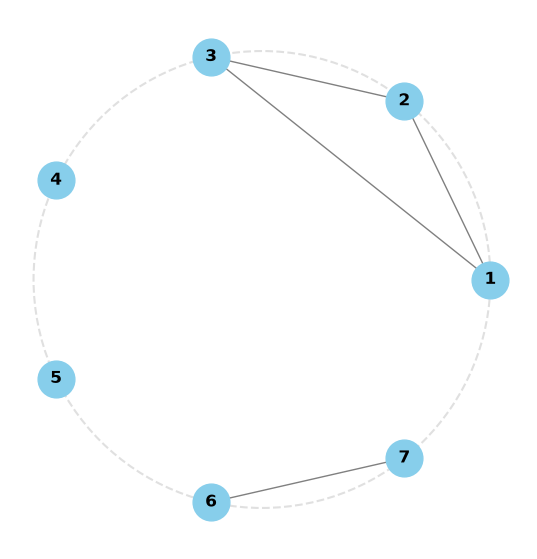

{1: [1, 2, 3], 2: [4], 3: [5], 4: [6, 7]}
4


In [139]:
adj_graph = graphicalSequenceToAdjacentList([4,3,3,2,2,1,1])
new_adj_graph = deleteEdge(adj_graph, (3,5))
print(adj_graph)
print(new_adj_graph)
adj_graph = deleteEdge(new_adj_graph, (1,4))
adj_graph = deleteEdge(adj_graph, (1,5))
adj_graph = deleteEdge(adj_graph, [2,4])
graphDisplay(adj_graph)
print(graphComponents(adj_graph))
print(len(graphComponents(adj_graph)))

In [140]:
# Euler cycle

def eulerCycle_R(adjacent_list=None, euler_cycle_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if euler_cycle_list == None:
        raise ValueError("Euler cycle list in format [node, node] (nodes index 1..n) required!")

    current_node = euler_cycle_list[-1]
    neighbors = adjacent_list[current_node - 1]

    if not neighbors:
        return euler_cycle_list

    next_node = None
    # Only one edge (bridge)
    if len(neighbors) == 1:
        next_node = neighbors[0]
    else:
        for node in neighbors:
            temp_adj_list = deleteEdge(adjacent_list, (current_node, node))
            components = graphComponents(temp_adj_list)

            same_component = False
            for _, nodes in components.items():
                if current_node in nodes and node in nodes:
                    same_component = True
                    break

            if same_component:
                next_node = node
                break

    # Fallback if all edges are bridges
    if next_node is None:
        next_node = neighbors[0]

    euler_cycle_list.append(next_node)
    new_adjacent_list = deleteEdge(adjacent_list, (current_node, next_node))
    return eulerCycle_R(new_adjacent_list, euler_cycle_list)
    

def findEulerCycle(adjacent_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")

    total_edges = 0
    for neighbors in adjacent_list:
        node_degree = len(neighbors)
        total_edges += node_degree
        if node_degree % 2 != 0 or node_degree == 0:
            return False, [] # Edges should be even for Euler cycle

    total_edges = total_edges // 2
    
    # Create copy to not modify passed graph
    output_adjacent_list = [[node for node in adjacent_list[i]] for i in range(len(adjacent_list))]

    # Start with first node index 1..n
    euler_cycle = [1]
    result = eulerCycle_R(output_adjacent_list, euler_cycle)

    if len(result) - 1 == total_edges:
        return True, result

    return False, []

# Generated by LLM
# def graphDisplayEulerCycle(euler_cycle, filename="euler_cycle_output.jpg"):
#     if not euler_cycle or len(euler_cycle) < 2:
#         raise ValueError("Euler cycle list must contain at least 2 nodes!")

#     graph = nx.DiGraph()
#     unique_nodes = set(euler_cycle)
#     graph.add_nodes_from(unique_nodes)

#     edge_labels = {}
#     for step in range(len(euler_cycle) - 1):
#         u = euler_cycle[step]
#         v = euler_cycle[step + 1]
#         graph.add_edge(u, v)
        
#         edge_key = (u, v)
#         if edge_key in edge_labels:
#             edge_labels[edge_key] += f", {step + 1}"
#         else:
#             edge_labels[edge_key] = str(step + 1)

#     fig, ax = plt.subplots(figsize=(8, 8))
#     pos = nx.circular_layout(graph)

#     # Add background circle
#     # nx.circular_layout places nodes on a unit circle with radius = 1.0 centered at (0, 0)
#     bg_circle = plt.Circle(
#         (0, 0),
#         radius=1.0,
#         color="lightgray",
#         fill=False,
#         linestyle="--",
#         linewidth=1.5,
#         alpha=0.7,
#         zorder=1
#     )
#     ax.add_patch(bg_circle)

    # # Draw nodes and directed edges on top (zorder > 1)
    # nx.draw_networkx_nodes(
    #     graph, pos, node_color="skyblue", node_size=800, ax=ax
    # )
    # nx.draw_networkx_labels(
    #     graph, pos, font_size=12, font_weight="bold", ax=ax
    # )
    # nx.draw_networkx_edges(
    #     graph,
    #     pos,
    #     edge_color="gray",
    #     arrows=True,
    #     arrowsize=20,
    #     arrowstyle="-|>",
    #     connectionstyle="arc3,rad=0.15",
    #     ax=ax
    # )

    # nx.draw_networkx_edge_labels(
    #     graph,
    #     pos,
    #     edge_labels=edge_labels,
    #     font_color="red",
    #     font_size=9,
    #     label_pos=0.3,
    #     rotate=False,
    #     ax=ax
    # )

    # plt.title("Eulerian Cycle Traversal Path", fontsize=14, fontweight="bold")
    # plt.axis("off")
    # ax.set_aspect("equal")  # Keeps the circle perfectly round
    
    # # plt.savefig(filename, bbox_inches="tight", dpi=300)
    # plt.show()
    # plt.close()

def graphDisplayEulerCycle(euler_cycle, filename="euler_cycle_output"):
    if not euler_cycle or len(euler_cycle) < 2:
        raise ValueError("Euler cycle list must contain at least 2 nodes!")

    graph = nx.DiGraph()
    graph.add_nodes_from(set(euler_cycle))

    # Step numbers on edges (in case an edge is used more than once, numbers are joined)
    edge_labels = {}
    for step in range(len(euler_cycle) - 1):
        u = euler_cycle[step]
        v = euler_cycle[step + 1]
        graph.add_edge(u, v)

        if (u, v) in edge_labels:
            edge_labels[(u, v)] += f", {step + 1}"
        else:
            edge_labels[(u, v)] = str(step + 1)

    _, ax = plt.subplots(figsize=(8, 8))
    pos = nx.circular_layout(graph)

    # Background circle
    bg_circle = plt.Circle(
        (0, 0),
        radius=1.0,
        color="lightgray",
        fill=False,
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        zorder=1,
    )
    ax.add_patch(bg_circle)

    # Blue directed edges (same style as the Hamilton cycle)
    nx.draw_networkx_edges(
        graph,
        pos,
        edge_color="blue",
        width=2.5,
        arrows=True,
        arrowsize=25,
        arrowstyle="-|>",
        node_size=800,  # arrowheads stop at the node border instead of hiding under it
        ax=ax,
    )

    # Nodes and labels on top
    nx.draw_networkx_nodes(
        graph, pos, node_color="skyblue", node_size=800, ax=ax
    )
    nx.draw_networkx_labels(
        graph, pos, font_size=12, font_weight="bold", ax=ax
    )

    # Step numbers in blue, with a white box so they stay readable over the lines
    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_color="blue",
        font_size=10,
        font_weight="bold",
        label_pos=0.35,
        rotate=False,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
        ax=ax,
    )

    plt.title("Eulerian Cycle Traversal Path", fontsize=14, fontweight="bold")
    plt.axis("off")
    ax.set_aspect("equal")

    # plt.savefig(f"{filename}.jpg", bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

True [1, 2, 3, 1, 4, 2, 5, 3, 4, 6, 7, 5, 1]


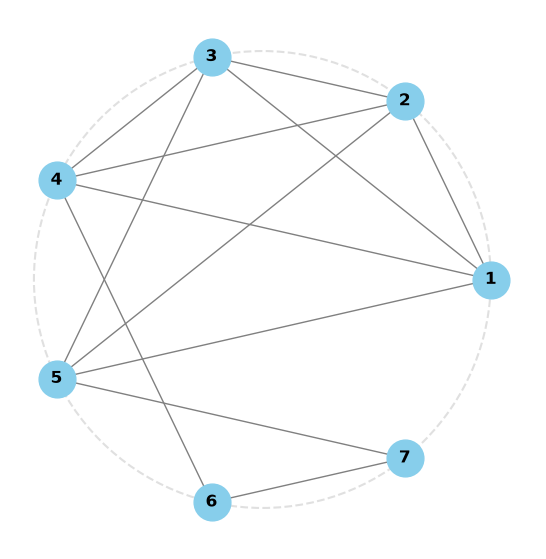

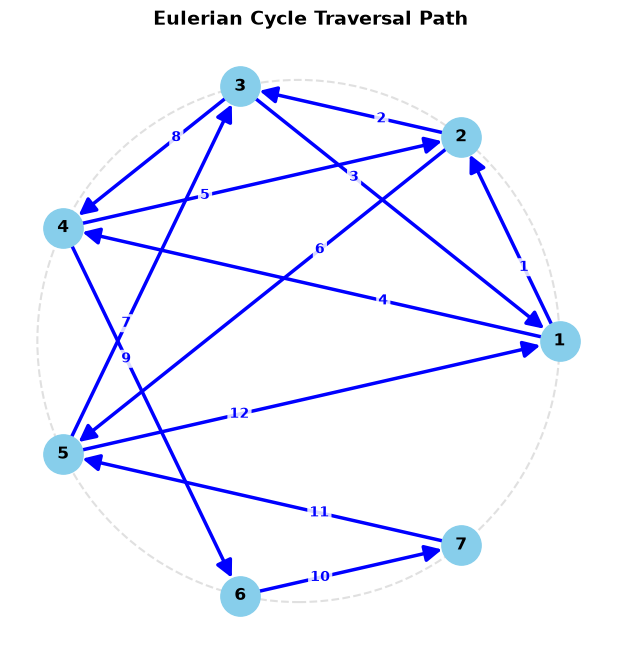

In [141]:
status, res = findEulerCycle(graphicalSequenceToAdjacentList([4, 4, 4, 4, 4, 2, 2]))
print(status, res)
graphDisplay(graphicalSequenceToAdjacentList([4, 4, 4, 4, 4, 2, 2]))
graphDisplayEulerCycle(res)

(True, [1, 2, 3, 1, 4, 5, 1])


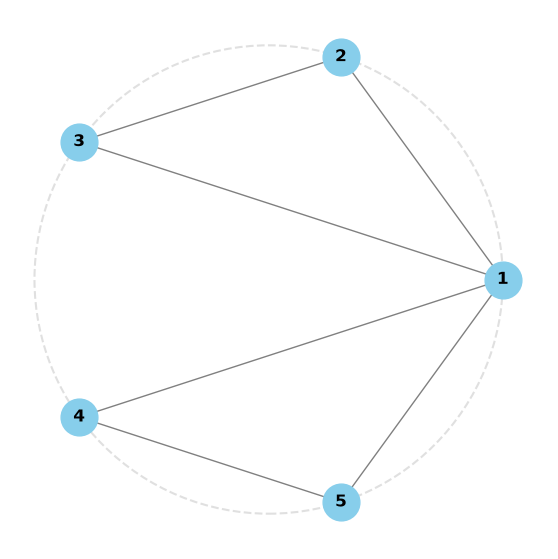

In [142]:
adjacent_list_test = [
    [2,3,4,5],
    [1,3],
    [1,2],
    [1,5],
    [1,4]
]
print(findEulerCycle(adjacent_list_test))
graphDisplay(adjacent_list_test)

True [1, 2, 5, 3, 4, 5, 1]


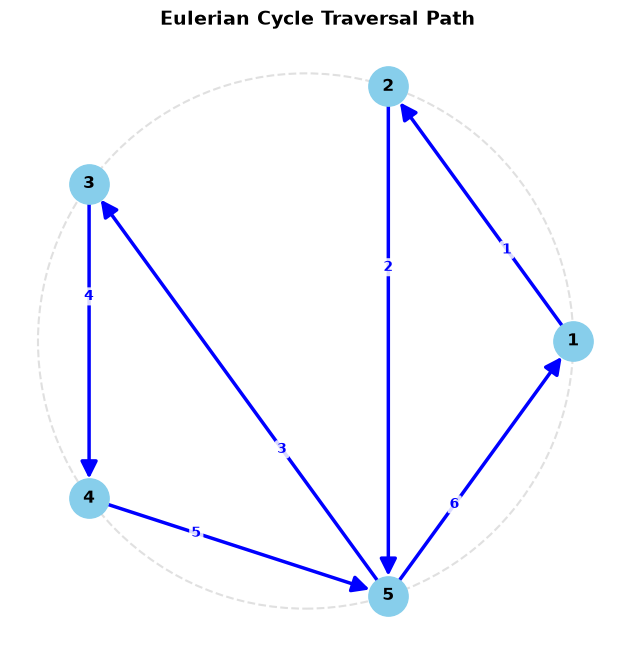

In [143]:
adjacent_list_test_hard = [
    [2,5],
    [1,5],
    [4,5],
    [3,5],
    [1,2,3,4]
]
status, res = findEulerCycle(adjacent_list_test_hard)
print(status, res)
# graphDisplay(adjacent_list_test_hard)
graphDisplayEulerCycle(res)

True [1, 2, 3, 1, 4, 2, 5, 4, 3, 7, 6, 5, 1]


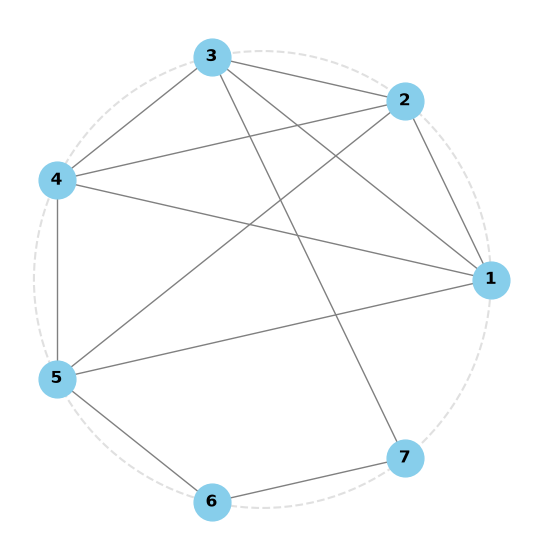

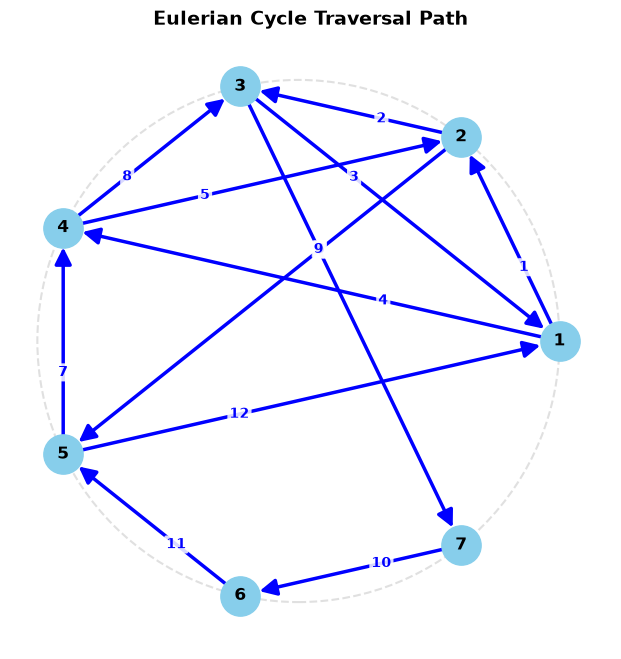

In [144]:
adjacent_list_test_hard = [
    [2,3,4,5],
    [1,3,4,5],
    [1,2,4,7],
    [1,2,3,5],
    [1,2,4,6],
    [5,7],
    [3,6]
]
status, res = findEulerCycle(adjacent_list_test_hard)
print(status, res)
graphDisplay(adjacent_list_test_hard)
graphDisplayEulerCycle(res)

In [145]:
# k regular generation
def generateGraphRegularK(node_num=None, node_degree=None, randomization_cycles=None):
    if node_num == None:
        raise ValueError("Node number required!")
    if node_degree == None:
        raise ValueError("Node degree required!")

    node_num = int(node_num)
    node_degree = int(node_degree)

    if node_num <= node_degree:
        raise ValueError("Node number must be greater than node degree!")
    if node_degree % 2 == 1 and node_num % 2 != 0:
        raise ValueError("For odd node degree, node number must be even")

    adjacent_list = graphicalSequenceToAdjacentList([node_degree for _ in range(node_num)])
    adjacent_list = randomize_pair(adjacent_list, randomization_cycles if randomization_cycles != None else 10)
    return adjacent_list

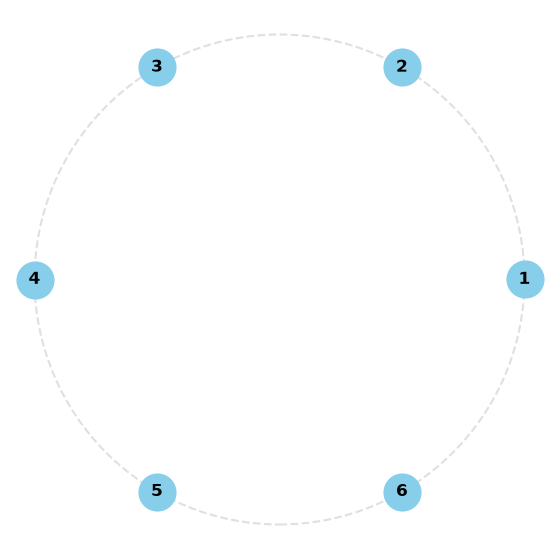

In [146]:
test = generateGraphRegularK(6, 0)
graphDisplay(test)

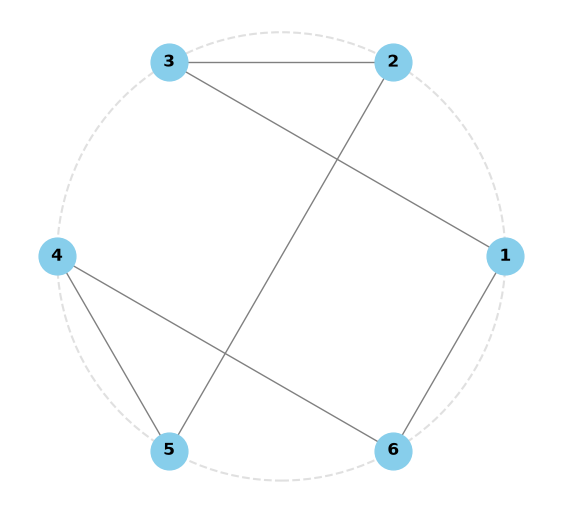

In [147]:
test = generateGraphRegularK(6, 2)
graphDisplay(test)

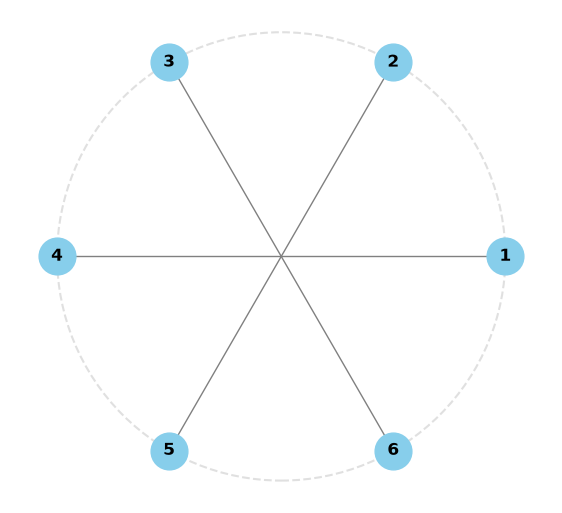

In [148]:
test = generateGraphRegularK(6, 1)
graphDisplay(test)

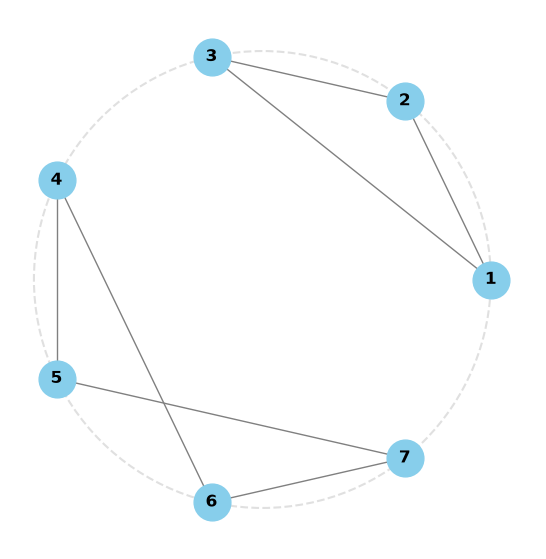

In [149]:
test = generateGraphRegularK(7, 2)
graphDisplay(test)

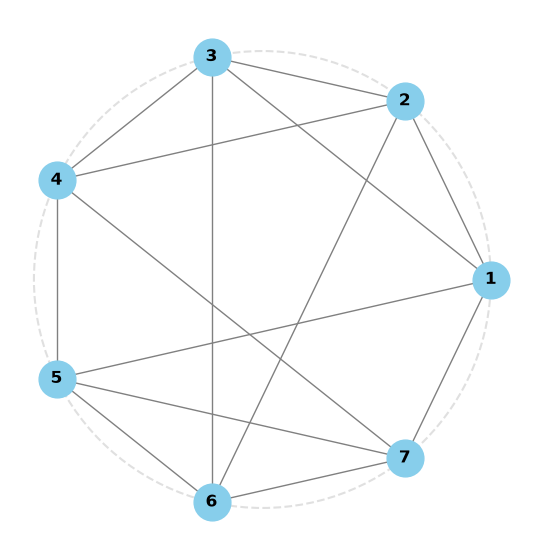

In [150]:
test = generateGraphRegularK(7, 4)
graphDisplay(test)

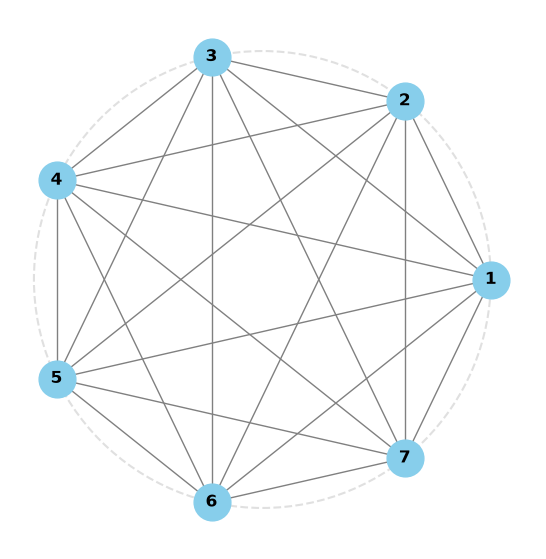

In [151]:
test = generateGraphRegularK(7, 6)
graphDisplay(test)

In [152]:
# Hamilton cycle

def hamiltonRecursive(adjacent_list=None, nodes=None, hamilton_path=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if nodes == None:
        raise ValueError("Nodes in format [visited (bool), ...] indexed 0...n required!")
    if hamilton_path == None:
        raise ValueError("Hamilton path as list of nodes [node_num, node_num, ...] index 1...n required!")

    # Check if final connection is right
    if len(hamilton_path) == len(adjacent_list):
        # We can connect end to start
        if hamilton_path[-1] in adjacent_list[hamilton_path[0] - 1]:
            hamilton_path.append(hamilton_path[0])
            return True
        else:
            return False
    
    # -1 changes indexing from 1...n to 0...n
    current_node = hamilton_path[-1] - 1
    visited_nodes = 0
    for node in adjacent_list[current_node]:
        if nodes[node - 1] == False:
            visited_nodes += 1
            # + 1 changes indexing fom 0...n to 1...n
            hamilton_path.append(node)
            nodes[node - 1] = True
            status = hamiltonRecursive(adjacent_list, nodes, hamilton_path)

            # If dead end we need return nodes and hamilton_path to previous status
            if status == False:
                visited_nodes -= 1
                nodes[node - 1] = False
                hamilton_path.remove(node)
            else:
                break
    # End without solution
    if visited_nodes == 0:
        return False
    
    return True


def findHamiltonCycle(adjacent_list=None):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")

    # [visited, ...] index 0...n
    nodes = [False for _ in range(len(adjacent_list))]

    # Start from node 1
    hamilton_path = [1]
    nodes[0] = True
    status = hamiltonRecursive(adjacent_list, nodes, hamilton_path)

    if status == True:
        return True, hamilton_path
    else:
        return False, [] 


def hamiltonCycleDisplay(adjacent_list=None, hamilton_cycle=None, filename="hamilton_cycle_output.jpg"):
    if adjacent_list == None:
        raise ValueError("Adjacent list required!")
    if hamilton_cycle == None:
        raise ValueError("Hamilton cycle in format [node_num, node_num] index 1...n required!")
    
    graph = nx.Graph()
    # Add 1-indexed nodes
    for i in range(len(adjacent_list)):
        graph.add_node(i + 1)

    # Add all edges from adjacency list
    for index, row in enumerate(adjacent_list):
        for neighbor in row:
            graph.add_edge(neighbor, index + 1)

    # 2. Extract directed edges for the Hamiltonian Cycle path
    cycle_edges = []
    cycle_length = len(hamilton_cycle)
    for i in range(cycle_length):
        u = hamilton_cycle[i]
        # Connect to next node (wrap around to the start if cycle isn't explicit)
        v = hamilton_cycle[(i + 1) % cycle_length]

        # Ignore redundant trailing connection if hamilton_cycle already repeats start node
        if i == cycle_length - 1 and u == v:
            continue

        cycle_edges.append((u, v))

    # Separate base edges from Hamiltonian cycle edges (undirected check)
    cycle_edges_set = {
        tuple(sorted([u, v])) for u, v in cycle_edges
    }
    non_cycle_edges = [
        (u, v)
        for u, v in graph.edges()
        if tuple(sorted([u, v])) not in cycle_edges_set
    ]

    # 3. Setup Layout and Canvas
    fig, ax = plt.subplots(figsize=(8, 8))
    pos = nx.circular_layout(graph)

    # Add background circle
    bg_circle = plt.Circle(
        (0, 0),
        radius=1.0,
        color="lightgray",
        fill=False,
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        zorder=1,
    )
    ax.add_patch(bg_circle)

    # 4. Draw Graph Components
    # Base non-cycle undirected edges
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=non_cycle_edges,
        edge_color="gray",
        alpha=0.5,
        width=1.5,
        ax=ax,
    )

    # Highlight Hamiltonian Cycle directed edges (Green with Arrows)
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=cycle_edges,
        edge_color="green",
        width=2.5,
        arrows=True,
        arrowsize=25,
        arrowstyle="-|>",
        ax=ax,
    )

    # Draw Nodes and Labels on top
    nx.draw_networkx_nodes(
        graph, pos, node_color="skyblue", node_size=800, ax=ax
    )
    nx.draw_networkx_labels(
        graph, pos, font_size=12, font_weight="bold", ax=ax
    )

    # 5. Final Adjustments
    plt.title(
        "Hamiltonian Cycle Traversal Path", fontsize=14, fontweight="bold"
    )
    plt.axis("off")
    ax.set_aspect("equal")

    # plt.savefig(filename, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

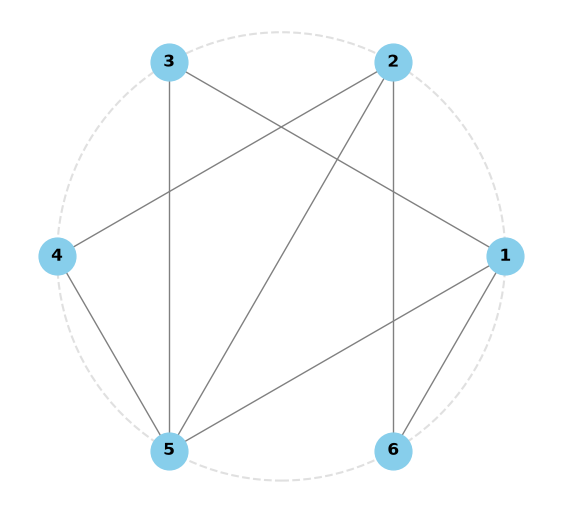

True [1, 6, 2, 4, 5, 3, 1]


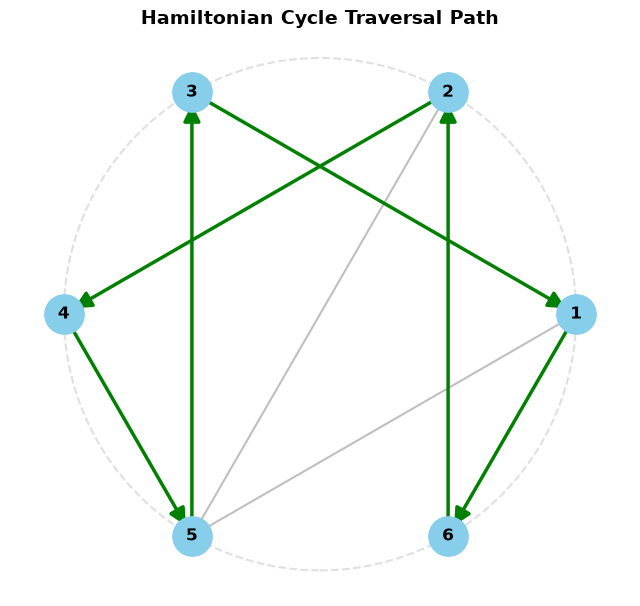

In [153]:
hamilton_graph = [
    [3,5,6],
    [4,5,6],
    [1,5],
    [2,5],
    [1,2,3],
    [1,2]
]

graphDisplay(hamilton_graph)
status, res = findHamiltonCycle(hamilton_graph)
print(status, res)
if status == True:
    hamiltonCycleDisplay(hamilton_graph, res)

In [154]:
def graphDisplayComponents(
    adjacent_list=None, components=None, filename="output_components"
):
    if adjacent_list is None:
        raise ValueError("Adjacent list required!")
    if components is None:
        raise ValueError("Components as dictionary class required!")

    # 1. Construct 1-indexed undirected graph from adjacency list
    graph = nx.Graph()
    for i in range(len(adjacent_list)):
        graph.add_node(i + 1)

    for index, row in enumerate(adjacent_list):
        for neighbor in row:
            graph.add_edge(neighbor, index + 1)

    # 2. Invert components dictionary to map node -> component ID
    node_to_comp = {}
    for comp_id, node_list in components.items():
        for node in node_list:
            node_to_comp[node] = comp_id

    # 3. Map component IDs to distinct colors from a colormap (Updated for Matplotlib 3.7+)
    unique_components = list(components.keys())
    cmap = plt.colormaps["tab10"].resampled(max(len(unique_components), 1))
    comp_color_map = {
        comp_id: cmap(idx) for idx, comp_id in enumerate(unique_components)
    }

    # Assign node colors based on their component
    node_colors = [
        comp_color_map.get(node_to_comp.get(node), "lightgray")
        for node in graph.nodes()
    ]

    # 4. Setup Layout and Canvas
    _, ax = plt.subplots(figsize=(8, 8))
    pos = nx.circular_layout(graph)

    bg_circle = plt.Circle(
        (0, 0),
        radius=1.0,
        color="lightgray",
        fill=False,
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        zorder=1,
    )
    ax.add_patch(bg_circle)

    # 5. Draw Edges, Nodes, and Labels
    nx.draw_networkx_edges(
        graph, pos, edge_color="gray", alpha=0.6, width=1.5, ax=ax
    )

    nx.draw_networkx_nodes(
        graph, pos, node_color=node_colors, node_size=800, ax=ax
    )

    nx.draw_networkx_labels(
        graph, pos, font_size=12, font_weight="bold", ax=ax
    )

    # 6. Title and Save
    plt.title("Graph Connected Components", fontsize=14, fontweight="bold")
    plt.axis("off")
    ax.set_aspect("equal")

    plt.savefig(f"{filename}.jpg", bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

2


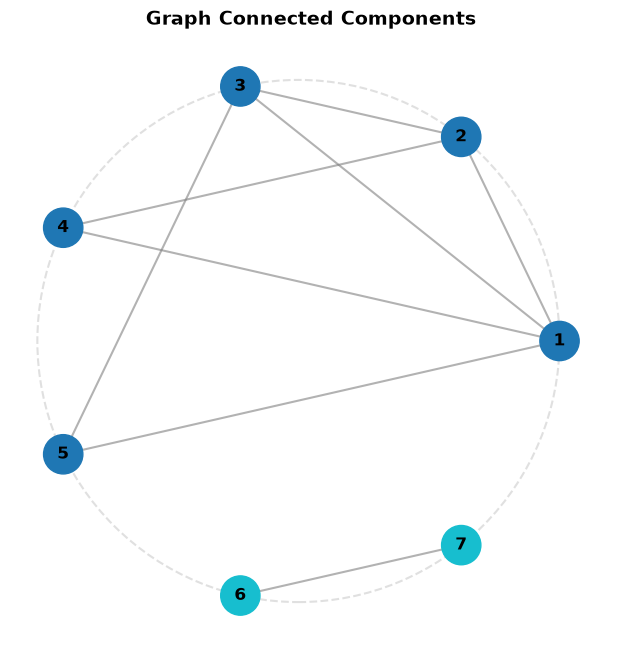

In [155]:
adj_graph = graphicalSequenceToAdjacentList([4,3,3,2,2,1,1])
components = graphComponents(adj_graph)
print(len(graphComponents(adj_graph)))

graphDisplayComponents(adj_graph, components)

In [193]:
def euler_sequence(nodes=None, max_tries=1000):
    if nodes == None or nodes <= 2:
        raise ValueError("Number >= 3 of nodes required!")

    evens = list(range(0, nodes, 2))

    for _ in range(max_tries):
        seq = [random.choice(evens) for _ in range(nodes)]
        if checkIfGraphicSequence(seq):
            adj_graph = graphicalSequenceToAdjacentList(sequence=seq)
            status, _ = findEulerCycle(adjacent_list=adj_graph)
            if status == True:
                return seq

    return [2] * nodes 



[1, 2, 3, 1, 4, 2, 5, 3, 4, 5, 1, 6, 2, 8, 7, 1]


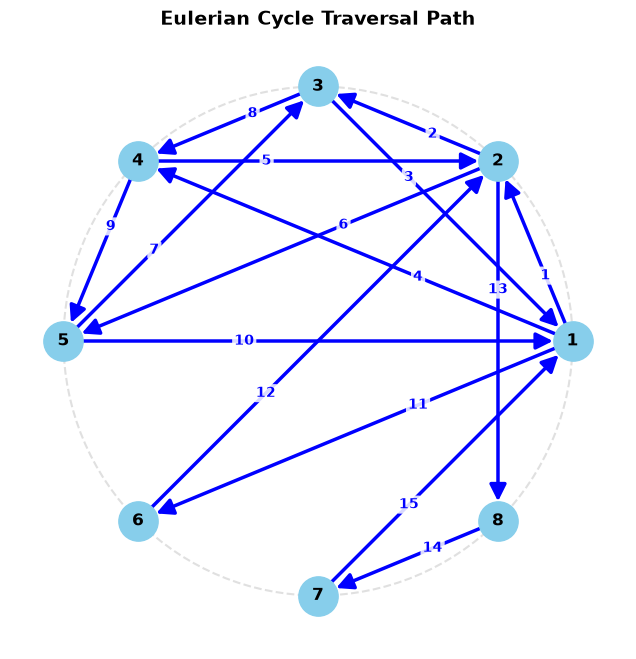

In [215]:
sequence = euler_sequence(8)
adj_graph = graphicalSequenceToAdjacentList(sequence)
status, cycle = findEulerCycle(adjacent_list=adj_graph)
if status:
    print(cycle)
    graphDisplayEulerCycle(euler_cycle=cycle)